# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

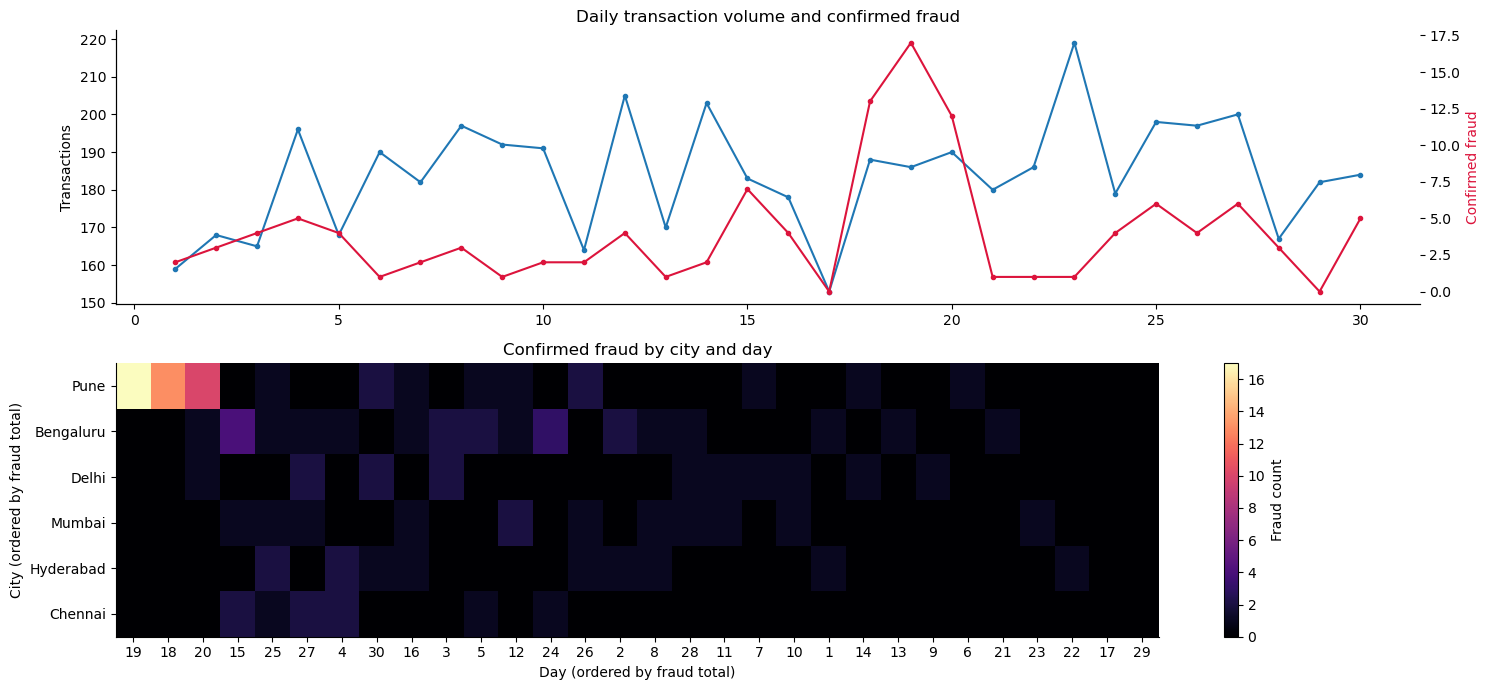

Highest-fraud city/day cells:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
           3       2
Pune       26      2
Bengaluru  2       2
           5       2
Pune       30      2
dtype: int64


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))

daily = tx.groupby("day").agg(transactions=("txn_id", "size"), fraud=("is_fraud", "sum"))
axes[0].plot(daily.index, daily.transactions, marker="o", ms=3, label="all transactions")
axes[0].set_ylabel("Transactions")
ax_fraud = axes[0].twinx()
ax_fraud.plot(daily.index, daily.fraud, color="crimson", marker="o", ms=3, label="confirmed fraud")
ax_fraud.set_ylabel("Confirmed fraud", color="crimson")
axes[0].set_title("Daily transaction volume and confirmed fraud")

heat = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index, heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat, aspect="auto", cmap="magma")
axes[1].set_yticks(range(len(heat.index)), heat.index)
axes[1].set_xticks(range(len(heat.columns)), heat.columns)
axes[1].set_xlabel("Day (ordered by fraud total)"); axes[1].set_ylabel("City (ordered by fraud total)")
axes[1].set_title("Confirmed fraud by city and day")
fig.colorbar(im, ax=axes[1], label="Fraud count")

plt.tight_layout(); plt.show()
print("Highest-fraud city/day cells:")
print(heat.stack().sort_values(ascending=False).head(10))


**Reflection:** What did the overview show that an alert list would not show?

**Your answer:** The daily chart and city-by-day heatmap show when fraud was concentrated and whether a place had a repeated pattern.
A score-sorted alert list would show individual suspicious cases, but not the wider time and location pattern.
This uses the overview-first idea and a reordered matrix to make clusters easier to notice.


## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

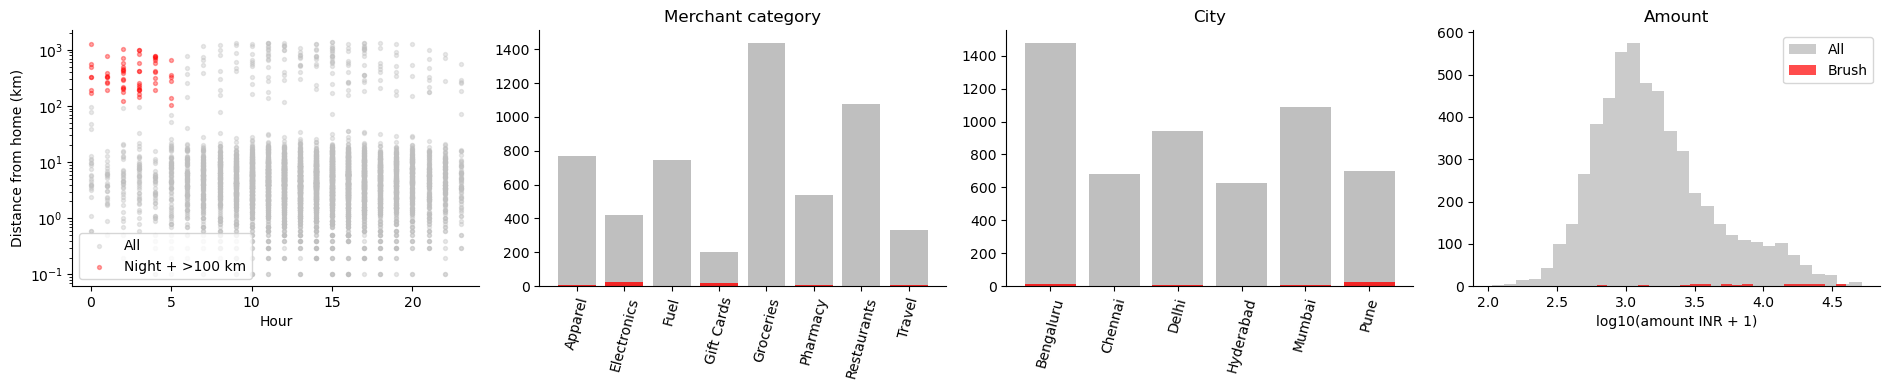

Brushed: 61; fraud rate: 86.885% vs overall 2.174%; share of all fraud: 44.167%


In [3]:
brush = (tx["night"] & (tx["distance_from_home_km"] > 100))

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for mask, color, label in [(~brush, "0.75", "All"), (brush, "red", "Night + >100 km")]:
    axes[0].scatter(tx.loc[mask, "hour"], tx.loc[mask, "distance_from_home_km"], s=8, alpha=0.35, c=color, label=label)
axes[0].set_yscale("log"); axes[0].set(xlabel="Hour", ylabel="Distance from home (km)"); axes[0].legend()

cat_all = tx["merchant_category"].value_counts().sort_index()
cat_brush = tx.loc[brush, "merchant_category"].value_counts().reindex(cat_all.index, fill_value=0)
axes[1].bar(cat_all.index, cat_all, color="0.75", label="All")
axes[1].bar(cat_brush.index, cat_brush, color="red", alpha=0.8, label="Brush")
axes[1].tick_params(axis="x", rotation=75); axes[1].set_title("Merchant category")

city_all = tx["city"].value_counts().sort_index()
city_brush = tx.loc[brush, "city"].value_counts().reindex(city_all.index, fill_value=0)
axes[2].bar(city_all.index, city_all, color="0.75")
axes[2].bar(city_brush.index, city_brush, color="red", alpha=0.8)
axes[2].tick_params(axis="x", rotation=75); axes[2].set_title("City")

axes[3].hist(np.log10(tx.loc[~brush, "amount_inr"] + 1), bins=30, color="0.75", alpha=0.8, label="All")
axes[3].hist(np.log10(tx.loc[brush, "amount_inr"] + 1), bins=30, color="red", alpha=0.7, label="Brush")
axes[3].set_xlabel("log10(amount INR + 1)"); axes[3].set_title("Amount"); axes[3].legend()

plt.tight_layout(); plt.show()
brush_fraud_rate = tx.loc[brush, "is_fraud"].mean()
overall_fraud_rate = tx["is_fraud"].mean()
fraud_share = tx.loc[brush, "is_fraud"].sum() / tx["is_fraud"].sum()
print(f"Brushed: {brush.sum():,}; fraud rate: {brush_fraud_rate:.3%} vs overall {overall_fraud_rate:.3%}; share of all fraud: {fraud_share:.3%}")


**Reflection:** What does the brush reveal about this rule?

**Your answer:** The rule may have a high fraud rate, but it captures only the fraud that is both at night and far from home.
That means it can miss many genuine fraud cases during the day or close to home, so it should not be used alone.
The city and merchant-category views help show where the remaining fraud is distributed.


## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

mask = (big.detector_score >= 0.6) & (big.amount_inr > 3000)
times = []
for _ in range(5):
    start = time.perf_counter()
    _ = big.loc[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    times.append(time.perf_counter() - start)
best_s = min(times)

per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (best_s / len(big))

t_50m = 50_000_000 * best_s / len(big)
skip_pct = max(0.0, (1 - max_rows / 50_000_000) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")


1,004,640 rows in 10.6 ms -> 0.0105 us/row -> max 9,513,456 rows in 0.1 s
50M rows -> 0.53 s; must skip 81.0% of rows to stay under 0.1 s


**Reflection:** Name one reduce technique and its cost.

**Your answer:** Pre-aggregation can store totals by day, city, or score range so the slider searches a much smaller table.
This keeps the interaction fast on 50 million rows.
The analyst loses transaction-level detail until they drill down into a selected group.


## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

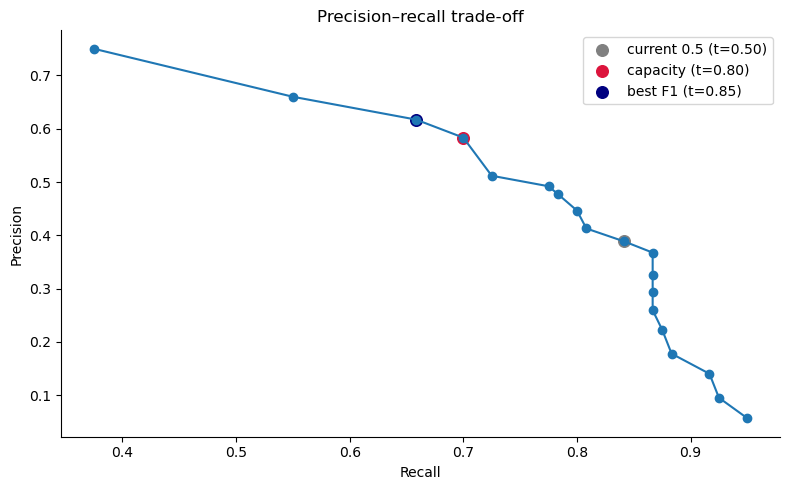

Recommend threshold 0.80: 144 alerts, precision 0.583, recall 0.700; best F1 is 0.85.


In [5]:
rows = []
y_true = tx.is_fraud.to_numpy()
for threshold in np.arange(0.05, 1.0, 0.05):
    predicted = tx.detector_score.to_numpy() >= threshold
    tp = int((predicted & (y_true == 1)).sum())
    fp = int((predicted & (y_true == 0)).sum())
    fn = int((~predicted & (y_true == 1)).sum())
    alerts = int(predicted.sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    rows.append({"threshold": threshold, "alerts": alerts, "tp": tp, "fp": fp, "fn": fn,
                 "precision": precision, "recall": recall, "f1": f1})

pr = pd.DataFrame(rows)
capacity_choice = pr[pr.alerts <= 150].sort_values(["recall", "threshold"], ascending=[False, True]).iloc[0]
best_f1 = pr.loc[pr.f1.idxmax()]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, marker="o")
for row, label, color in [(pr.loc[pr.threshold.sub(0.5).abs().idxmin()], "current 0.5", "grey"), (capacity_choice, "capacity", "crimson"), (best_f1, "best F1", "navy")]:
    ax.scatter(row.recall, row.precision, color=color, s=70, label=f"{label} (t={row.threshold:.2f})")
ax.set(xlabel="Recall", ylabel="Precision", title="Precision–recall trade-off"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Recommend threshold {capacity_choice.threshold:.2f}: {int(capacity_choice.alerts)} alerts, precision {capacity_choice.precision:.3f}, recall {capacity_choice.recall:.3f}; best F1 is {best_f1.threshold:.2f}.")


**Reflection:** Who should choose the final threshold?

**Your answer:** The Head of Fraud Ops should make the final decision with help from the model results.
The model can report precision, recall, F1, and alert volume, but it cannot know the team’s workload or the cost of missing a fraud case.
Visual analytics keeps a human involved so the threshold fits real operational priorities.


## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
flagged = tx[tx.detector_score >= 0.3].copy()
fig = px.scatter(flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
                 hover_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"],
                 title="Flagged transactions (score ≥ 0.3)")
fig.update_layout(dragmode="select")
fig.show()

sun = flagged.groupby(["city", "merchant_category"], as_index=False).agg(
    transactions=("txn_id", "size"), fraud_rate=("is_fraud", "mean"))
fig_sunburst = px.sunburst(sun, path=["city", "merchant_category"], values="transactions", color="fraud_rate",
                           color_continuous_scale="Reds", title="Flagged transactions: city → merchant category")
fig_sunburst.show()


**Reflection:** Why are tooltips frustrating for an overview?

**Your answer:** Tooltips require the investigator to inspect cases one at a time, so patterns across hundreds of alerts are hard to compare.
This is slow and places too much load on memory.
The overview heatmap and linked views solve this by showing distributions first, with tooltips reserved for details-on-demand.


## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

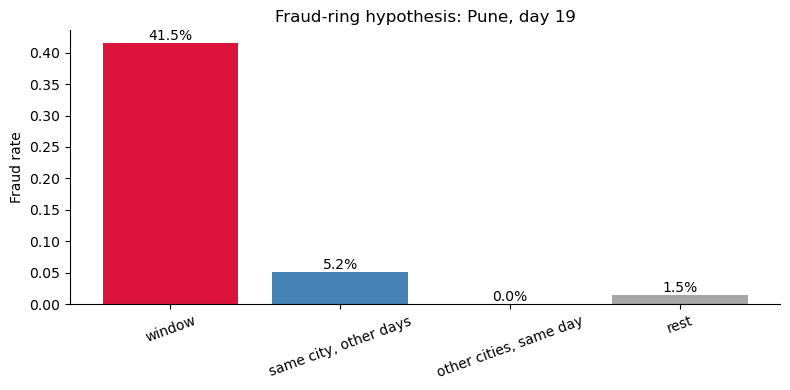

Hypothesis: fraud cluster in Pune on day 19; window rate 41.463%, outside 1.880%, chi-square p=3.524e-63
Counter-example rates: {'window': '41.463%', 'same city, other days': '5.159%', 'other cities, same day': '0.000%', 'rest': '1.476%'}
Verdict: evidence supports a localized cluster


In [7]:
from scipy.stats import chi2_contingency

fraud_totals = tx.groupby(["city", "day"]).is_fraud.sum().sort_values(ascending=False)
hypothesis_city, hypothesis_day = fraud_totals.index[0]
in_window = (tx.city == hypothesis_city) & (tx.day == hypothesis_day)

contingency = pd.crosstab(in_window, tx.is_fraud)
chi2, p_value, _, _ = chi2_contingency(contingency)
rate = lambda mask: tx.loc[mask, "is_fraud"].mean()
window_rate = rate(in_window)
city_other_days = (tx.city == hypothesis_city) & ~in_window
other_cities_same_day = (tx.day == hypothesis_day) & ~in_window
rest = ~in_window & ~city_other_days & ~other_cities_same_day
groups = {"window": in_window, "same city, other days": city_other_days,
          "other cities, same day": other_cities_same_day, "rest": rest}
rates = {name: rate(mask) for name, mask in groups.items()}

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(list(rates), list(rates.values()), color=["crimson", "steelblue", "darkorange", "0.65"])
ax.set_ylabel("Fraud rate"); ax.set_title(f"Fraud-ring hypothesis: {hypothesis_city}, day {hypothesis_day}")
ax.tick_params(axis="x", rotation=20)
for x, (name, value) in enumerate(rates.items()): ax.text(x, value, f"{value:.1%}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

print(f"Hypothesis: fraud cluster in {hypothesis_city} on day {hypothesis_day}; window rate {window_rate:.3%}, outside {rate(~in_window):.3%}, chi-square p={p_value:.4g}")
print("Counter-example rates:", {name: f"{value:.3%}" for name, value in rates.items()})
print("Verdict:", "evidence supports a localized cluster" if p_value < 0.05 and window_rate > rate(~in_window) else "insufficient evidence for a localized fraud ring")


**Reflection:** Which counter-example could kill the hypothesis?

**Your answer:** If the same city had a similarly high fraud rate on other days, the one-day city cluster would not be special.
That would support a city-wide problem or a local customer pattern rather than a temporary fraud ring.
If other cities were high on the same day, the stronger explanation would be a system-wide event or detector issue.


## Task 7 — The Decision (No Code)

**Your final note:** The month contained confirmed fraud concentrated in a small number of city-and-day cells, while the night-time and far-from-home rule identified only part of all fraud.
I recommend the capacity-constrained threshold selected in Task 4 because it keeps alerts within 150 while balancing precision and recall; the Head of Fraud Ops should approve the final trade-off.
The first tool should be the linked overview dashboard with the heatmap, brushing, and drill-down details, following overview first and details-on-demand.
For 50 million rows, pre-aggregation or indexing is needed to meet the 0.1-second dynamic-query goal.
Finally, investigators should label reviewed alerts and feed those outcomes back into retraining and threshold review next month.
